# EDA

In [1]:
# library import
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# importing data loaders
import data_loaders as dl

In [2]:
# initializing data loader
loader = dl.DataLoader()

### Day ahead prices

In [3]:
# starigg EDA on the day ahead data
dap = loader.day_ahead_price_data

In [4]:
print('=== Day Ahead Price Data ========')
print(f'Shape: {dap.shape}')
print(f'Columns: {dap.columns}')
print(f'Null values: {dap.isnull().sum().sum()}')
print(f'Duplicated values: {dap.duplicated().sum()}')
print(f'Data types: {dap.dtypes}')
print(f'Statistics: {dap.describe()}')
print('=================================')

=== Day Ahead Price Data ========
Shape: (103062, 2)
Columns: Index(['date', 'Day-ahead price (EUR/MWh)'], dtype='str')
Null values: 0
Duplicated values: 0
Data types: date                         datetime64[us, UTC]
Day-ahead price (EUR/MWh)                float64
dtype: object
Statistics:        Day-ahead price (EUR/MWh)
count              103062.000000
mean                   59.492173
std                    67.356150
min                   -61.840000
25%                    25.360000
50%                    40.770000
75%                    69.080000
max                   898.250000


In [5]:
# fixing column name
dap['price'] = dap['Day-ahead price (EUR/MWh)']
dap = dap.drop(columns=['Day-ahead price (EUR/MWh)'])

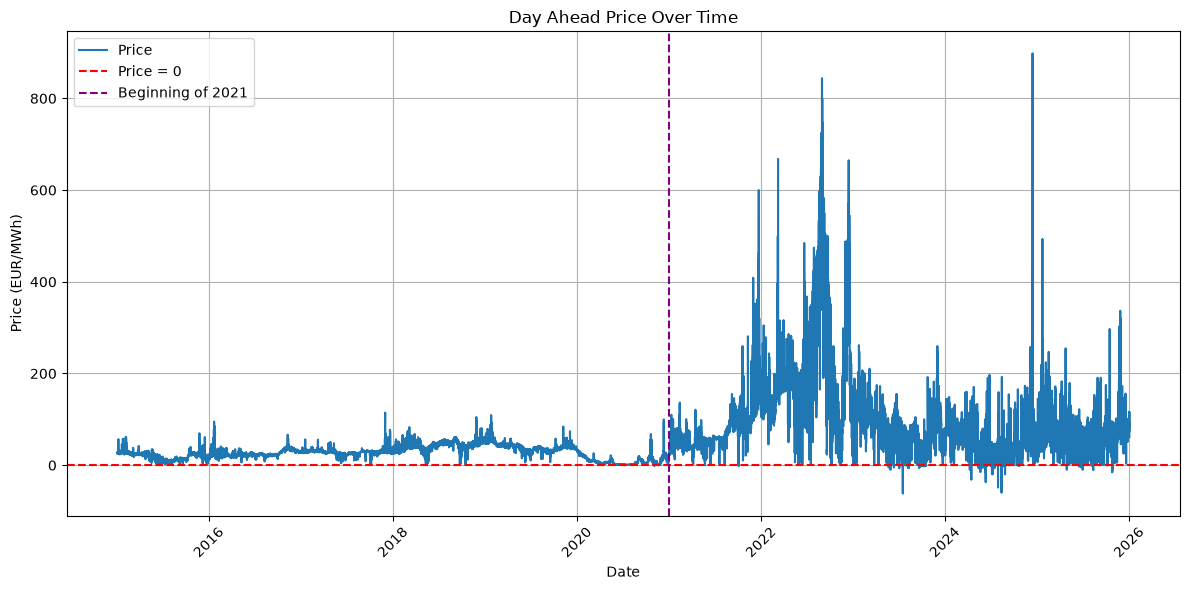

In [51]:
# plotting price over time
dap['date'] = pd.to_datetime(dap['date'], utc=True)
plt.figure(figsize=(12, 6))
sns.lineplot(x=dap['date'], y=dap['price'], label='Price')

# adding an orizotal line at y=0
plt.axhline(y=0, color='r', linestyle='--', label='Price = 0')

# adding a vertical line at the beginning of 2021
plt.axvline(x=pd.Timestamp('2021-01-01 00:00:00', tz='UTC'), color='purple', linestyle='--', label='Beginning of 2021')

# infos
plt.title('Day Ahead Price Over Time')
plt.xlabel('Date')
plt.ylabel('Price (EUR/MWh)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid()
plt.legend()
plt.show()

Until 2020 the price was low and smooth, whereas from 2021 onwards it became high, highly volatile. 
<br>
The main causes are:

Why it was calm before

- European energy crisis: Gas prices rose starting in 2021 and peaked with the invasion of Ukraine in 2022. 

- Low reservoirs: 2021–2022 was drier in southern Norway, and scarcer water holds a higher value, driving prices up.

<br>
Implications for the Model

- Distribution shift between train and test: The training set (2015–2022) contains five calm years and only two turbulent ones, while the test set (2023–2024) lies entirely within the volatile regime.

- Relative features: need to use features that do not depend on the absolute level—such as the price rank within the week, the price divided by the moving average, or the price relative to the water value.

In [ ]:
# confirming that the price are given each hour of the day
#  and there a not mid indexed hours
df = dap.copy()
df['date'] = pd.to_datetime(df['date'], utc=True)
dt = df['date'].diff()
print(dt.groupby(df['date'].dt.year).value_counts().unstack(fill_value=0))  
# timestap with step < 1h 
print(df.loc[dt < pd.Timedelta('1h'), 'date'].min())                         
n = df.groupby(df['date'].dt.date).size()
print()
print(n.groupby(pd.to_datetime(n.index).year).agg(['min', 'max']))
print('24 = day, 96 = 15 min)')



date  0 days 00:15:00  0 days 01:00:00
date                                  
2015                0             8759
2016                0             8784
2017                0             8760
2018                0             8760
2019                0             8760
2020                0             8784
2021                0             8760
2022                0             8760
2023                0             8760
2024                0             8784
2025             8839             6551
2025-09-30 22:15:00+00:00

      min  max
date          
2015   24   24
2016   24   24
2017   24   24
2018   24   24
2019   24   24
2020   24   24
2021   24   24
2022   24   24
2023   24   24
2024   24   24
2025   24   96
24 = day, 96 = 15 min)


The data timestep is hourly, for eavery year form 2015 to 2024 (except 2025 which is out of range 
for this project)

Since it is a timeseries let's analyze the timeseries elements

      daily  weekly
date               
2015   0.26    0.17
2016   0.18    0.11
2017   0.17    0.10
2018   0.29    0.14
2019   0.25    0.17
2020   0.06    0.05
2021   0.08    0.08
2022   0.13    0.16
2023   0.12    0.13
2024   0.08    0.11
{1: np.float64(0.99), 24: np.float64(0.94), 48: np.float64(0.91), 168: np.float64(0.88)}


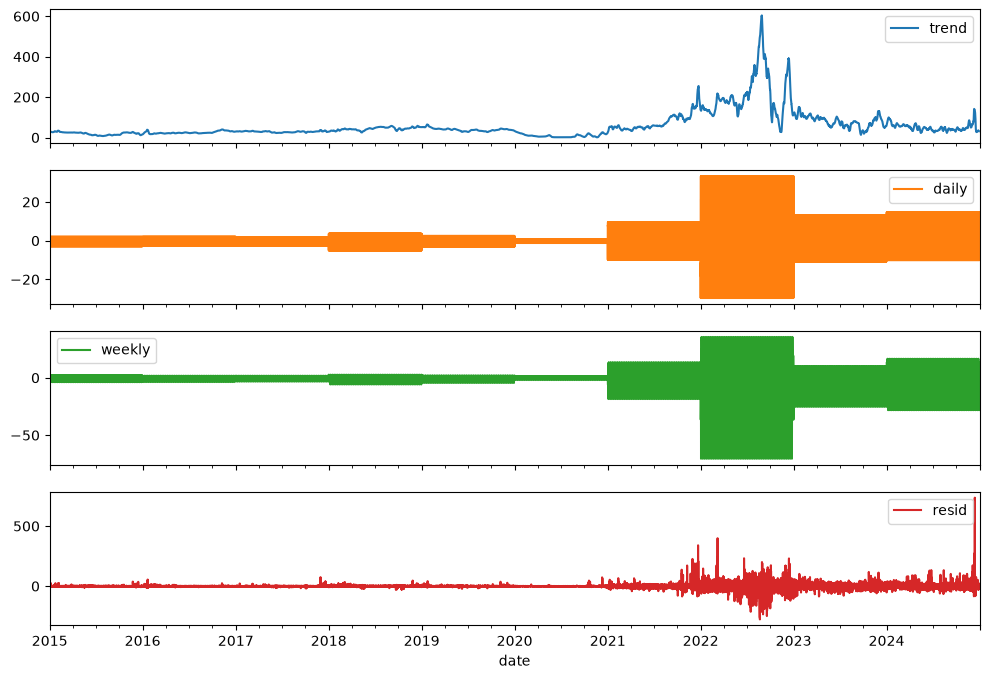

In [ ]:
# keeping only the data before 2025, and setting the date as index 
df = dap[dap['date'] < '2025-01-01'].set_index('date')['price'].asfreq('h')

# computing the trend
trend = df.rolling(168, center=True).mean()          

# excluding the trrend
d = df - trend

# lables
#   hour
how = d.index.dayofweek * 24 + d.index.hour         
#   year
y = d.index.year

# computing the seasonal components
#   hourly, daily, weekly
s168 = d.groupby([y, how]).transform('mean')        
daily = d.groupby([y, d.index.hour]).transform('mean')
weekly = s168 - daily

# computing the residuals
resid = d - s168

# creating a dataframe with all the components and plotting them    
comp = pd.DataFrame({'trend': trend, 'daily': daily, 'weekly': weekly, 'resid': resid})
comp.plot(subplots=True, figsize=(12, 8))

# forza della stagionalità per anno: 1 - Var(resid) / Var(componente + resid)
ok = comp.dropna()
# computng the strength of the seasonal components for each year
f = lambda g, c: max(0, 1 - g['resid'].var() / (g[c] + g['resid']).var())
print(ok.groupby(ok.index.year).apply(lambda g: pd.Series({c: f(g, c) for c in ['daily', 'weekly']})).round(2))

# autocorrelation of the residuals
print({l: round(df.autocorr(l), 2) for l in (1, 24, 48, 168)})   

What We Can See:

- Trend: The level ranges between 20 and 60 EUR/MWh until 2020, then rises from 2021 and peaks at around 600 EUR/MWh.

- Daily Seasonality: The amplitude is within a few EUR until 2020 and grows starting in 2021, peaking in 2022 In 2023–2024, it remains higher than before 2021.

- Weekly Seasonality: Follows the same pattern but with a greater amplitude (the day-of-the-week signal carries more weight than the hour-of-the-day signal).

- Residuals: Extremely small until 2020 and then exploding, showing non-constant variance (heteroscedasticity) and periods of concentrated volatility.

<br>
Implications for the Model:

- Normalized features are needed

- The intra-weekly signal truly matters from 2021: If the AUC of price alone is high only from 2021 onwards, this confirms it.

- Better to use block cross-validation that includes the years 2021–2022, and compare training on the entire dataset versus training only on the recent period.

- Spikes: Hours with extreme prices (hundreds of EUR) can dominate any non-robust statistic: using the weekly rank is preferable as it is unaffected by amplitude.